# Soft-DTW: a Differentiable Loss Function for Time-Series
Mini-project, ML for Time Series (MVA). Paper: Cuturi & Blondel, ICML 2017.

**Structure**
1. Method: our implementation of soft-DTW (forward, backward, gradient) and its verification
2. Data
3. Experiments: reproduction of the paper
4. Extension

The core is in `softdtw.py` (Numba) and `torch_sdtw.py` (PyTorch loss); the full test-suite is `tests.py` (`pytest tests.py`).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from softdtw import (sdtw_forward, sdtw_backward, soft_dtw, soft_dtw_alignment,
                     soft_dtw_value_and_grad, dtw, dtw_path, sqeuclidean_cost)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
rng = np.random.default_rng(0)

## 1. Method

### 1.1 Worked example (Algorithms 1 and 2 by hand)
Cost matrix $\Delta = \begin{pmatrix}1&3\\2&1\end{pmatrix}$, $\gamma=1$. There are three alignments (diagonal, via $(2,1)$, via $(1,2)$) with costs 2, 4, 5.
The backward matrix $E$ must equal the Gibbs probability that a path visits each cell.

In [2]:
D = np.array([[1.0, 3.0], [2.0, 1.0]])
R = sdtw_forward(D, 1.0)
E = sdtw_backward(D, R, 1.0)
p = np.exp(-np.array([2.0, 4.0, 5.0])); p /= p.sum()
print("dtw_gamma =", R[2, 2], "  (hard DTW = 2)")
print("E =\n", E.round(4))
print("Gibbs probabilities of the 3 paths (diag, via (2,1), via (1,2)):", p.round(4))

dtw_gamma = 1.8301539804437146   (hard DTW = 2)
E =
 [[1.     0.042 ]
 [0.1142 1.    ]]
Gibbs probabilities of the 3 paths (diag, via (2,1), via (1,2)): [0.8438 0.1142 0.042 ]


### 1.2 Verification
`tests.py` checks, among others:
* value and $E$ against **brute-force enumeration of all paths** (Delannoy many) for $n,m\le5$, $\gamma\in\{0.01,0.1,1,10\}$;
* the gradient against **finite differences**;
* the sandwich bound $\mathrm{dtw} - \gamma\log|\mathcal A_{n,m}| \le \mathrm{dtw}_\gamma \le \mathrm{dtw}$ (hence $\gamma\to0$ recovers DTW) and $E\to A^\star$;
* agreement with `tslearn`;
* the PyTorch custom backward against plain autograd, with batches and the chain rule.

In [3]:
import subprocess, sys
r = subprocess.run([sys.executable, "-m", "pytest", "tests.py", "-q", "--color=no", "-p", "no:cacheprovider"], capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])

35 passed in 10.03s


### 1.3 What the expected alignment $E$ looks like
Two noisy bumps, the second one shifted in time. For small $\gamma$, $E$ is the DTW path; as $\gamma$ grows it spreads over many alignments,
and for large $\gamma$ it is pulled towards the centre of the grid regardless of the data (the uniform distribution over paths concentrates there).

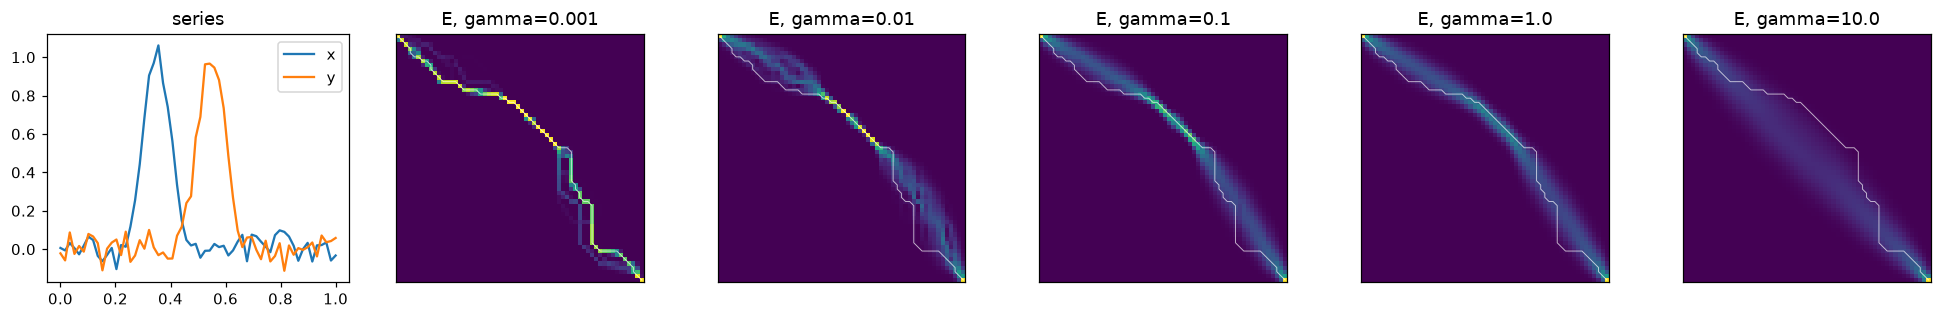

In [4]:
t = np.linspace(0, 1, 60)
x = np.exp(-((t - 0.35) / 0.07) ** 2) + 0.05 * rng.normal(size=t.size)
y = np.exp(-((t - 0.55) / 0.07) ** 2) + 0.05 * rng.normal(size=t.size)
A, _ = dtw_path(x, y)

gammas = [0.001, 0.01, 0.1, 1.0, 10.0]
fig, axes = plt.subplots(1, len(gammas) + 1, figsize=(3 * (len(gammas) + 1), 3))
axes[0].plot(t, x, label="x"); axes[0].plot(t, y, label="y"); axes[0].legend(); axes[0].set_title("series")
for ax, g in zip(axes[1:], gammas):
    _, E = soft_dtw_alignment(x, y, g)
    ax.imshow(E, cmap="viridis", origin="upper")
    ii, jj = np.nonzero(A)
    ax.plot(jj, ii, "w-", lw=0.6, alpha=0.7)
    ax.set_title(f"E, gamma={g}"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig("figures/E_vs_gamma.png", dpi=200); plt.show()

### 1.4 Computational cost
Forward + backward of our Numba implementation, compared with the same recursion in pure Python and with a cell-by-cell PyTorch forward differentiated by autograd.
All are $O(nm)$; the constant is what differs.

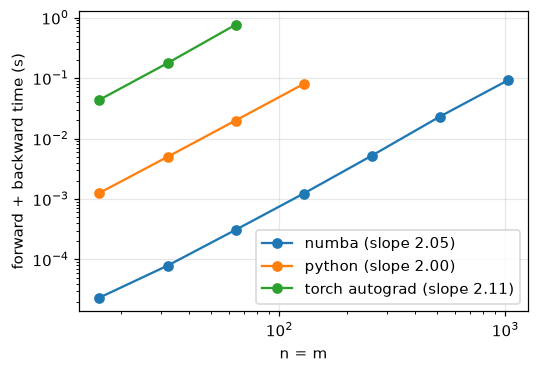

numba {16: np.float64(2e-05), 32: np.float64(8e-05), 64: np.float64(0.00031), 128: np.float64(0.00123), 256: np.float64(0.00518), 512: np.float64(0.02292), 1024: np.float64(0.09133)}
python {16: np.float64(0.00126), 32: np.float64(0.00497), 64: np.float64(0.01985), 128: np.float64(0.07958)}
torch autograd {16: np.float64(0.04372), 32: np.float64(0.17647), 64: np.float64(0.76013)}


In [5]:
import torch
from torch_sdtw import soft_dtw_torch_naive

fwd_py, bwd_py = sdtw_forward.py_func, sdtw_backward.py_func  # same code, not compiled

def timeit(f, repeat=3):
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter(); f(); best = min(best, time.perf_counter() - t0)
    return best

sizes = {"numba": [16, 32, 64, 128, 256, 512, 1024],
         "python": [16, 32, 64, 128],
         "torch autograd": [16, 32, 64]}
timings = {k: [] for k in sizes}
for name, ns in sizes.items():
    for n in ns:
        a, b = rng.normal(size=(n, 1)), rng.normal(size=(n, 1))
        Dn = sqeuclidean_cost(a, b)
        if name == "numba":
            f = lambda: sdtw_backward(Dn, sdtw_forward(Dn, 1.0), 1.0)
        elif name == "python":
            f = lambda: bwd_py(Dn, fwd_py(Dn, 1.0), 1.0)
        else:
            ta = torch.tensor(a, requires_grad=True); tb = torch.tensor(b)
            f = lambda: torch.autograd.grad(soft_dtw_torch_naive(ta, tb, 1.0), ta)
        timings[name].append(timeit(f, repeat=3 if n <= 256 else 1))

plt.figure(figsize=(5, 3.5))
for name, ns in sizes.items():
    slope = np.polyfit(np.log(ns[1:]), np.log(timings[name][1:]), 1)[0]
    plt.loglog(ns, timings[name], "o-", label=f"{name} (slope {slope:.2f})")
plt.xlabel("n = m"); plt.ylabel("forward + backward time (s)"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/timing.png", dpi=200); plt.show()
for name in sizes:
    print(name, dict(zip(sizes[name], np.round(timings[name], 5))))